# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx
from skewerjax.constants.physical_constants import phys
import skewerjax.cosmology.cosmology as cosmology

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget

INFO:2026-03-24 20:39:28,037:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-03-24 20:39:28,037 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-03-24 20:39:28,226 - INFO - SkewerBundle class definition complete


# Initialize cosmology class with 4 different cosmologies

In [2]:
# Create cosmology object
cosmo = cosmology.Cosmology(
    H0             = jnp.array([phys.H0, phys.H0, phys.H0, phys.H0]),
    Omega_r_0      = jnp.array([1.0, 0.0, 0.0, 9.1436e-5]),
    Omega_m_0      = jnp.array([0.0, 1.0, 0.0, 0.3089]),
    Omega_k_0      = jnp.array([0.0, 0.0, 0.0, 0.0]),
    Omega_lambda_0 = jnp.array([0.0, 0.0, 1.0, 0.6911]),
)

# Compute a(x) for the different cosmologies integrating forwards and backwards in time

### Define initial conditions and x for evaluating the a(x) ODE

In [3]:
a0 = 1.0
x0 = 0.0 # UNITS: [Mpc]

# initial conditions
ICs = jnp.array([a0, a0, a0, a0])

xf = x0 + 1/(a0 * phys.H0_over_c) # Dark Energy Domination divergence UNITS: [Mpc]
xf -= 1e-6

xi = x0 - 2/phys.H0_over_c * a0**0.5 # Dark Matter Fomination a' = 0 UNITS: [Mpc]
xi += 1e-6

NN_x = 1000
x_forward = jnp.linspace(x0, xf, NN_x)
x_backward = jnp.linspace(x0, xi, NN_x)

### Call the cosmo.solve_a_of_x method to obtain a(x)

In [4]:
results_forward = cosmo.solve_a_of_x(ICs, x_forward)
results_backward = cosmo.solve_a_of_x(ICs, x_backward)

# Compute analytical solution benchmark

In [5]:
x_analytic = jnp.linspace(xi, xf, 10000)

omega_k_positive = 1.0
analytic_solutions = {
    "Radiation": (x_analytic, a0 + phys.H0_over_c*(x_analytic - x0)), # phys.H0_over_c is in [1/Mpc], x_analytic is in [Mpc]
    "Matter": (x_analytic, (a0**0.5 + 0.5*phys.H0_over_c*(x_analytic - x0))**2),
    "Lambda": (x_analytic, (a0**-1 - phys.H0_over_c*(x_analytic - x0))**-1),
    "Planck-2018": None,
    # "Curvature": (x_analytic, jnp.exp( (phys.H0/(phys.cc_Gpc_per_Gyr*jnp.sqrt(jnp.abs(-omega_k_positive/phys.cc_Gpc_per_Gyr**2))))*(jnp.arcsinh(jnp.sqrt(jnp.abs(-omega_k_positive/phys.cc_Gpc_per_Gyr**2))*x_analytic) - jnp.arcsinh(jnp.sqrt(jnp.abs(-omega_k_positive/phys.cc_Gpc_per_Gyr**2))*x0)) +jnp.log(a0) ) ),
    # "Curvature_omega_k_negative": (x_analytic, jnp.exp( (H0/(cc*jnp.sqrt(jnp.abs(-omega_k_negative/cc**2))))*(jnp.arcsin(jnp.sqrt(jnp.abs(-omega_k_negative/cc**2))*x_analytic) - jnp.arcsin(jnp.sqrt(jnp.abs(-omega_k_negative/cc**2))*x0)) +jnp.log(a0) ) )
}


### Reshape the numerical solutions to be the same shape as the analytic solutions (from xi to xf concatenating the forward and backward solutions)

In [6]:
a_forward = np.array(results_forward)
a_backward = np.array(results_backward)
numerical_solutions = {}
for ii, key_cosmo in enumerate(list(analytic_solutions.keys())):
    numerical_solutions[key_cosmo] = (
        jnp.concatenate([x_backward[::-1], x_forward]),
        jnp.concatenate([a_backward[ii][::-1], a_forward[ii]])
    )

# Plot for comparing analytic vs numerical results

In [7]:
# Define color map for cosmologies
cosmo_colors = {
    "Radiation": "crimson",
    "Matter": "royalblue",
    "Lambda": "limegreen",
    "Planck-2018": "black",
    "Curvature": "orange",
    "Curvature_omega_k_negative": "purple"
}

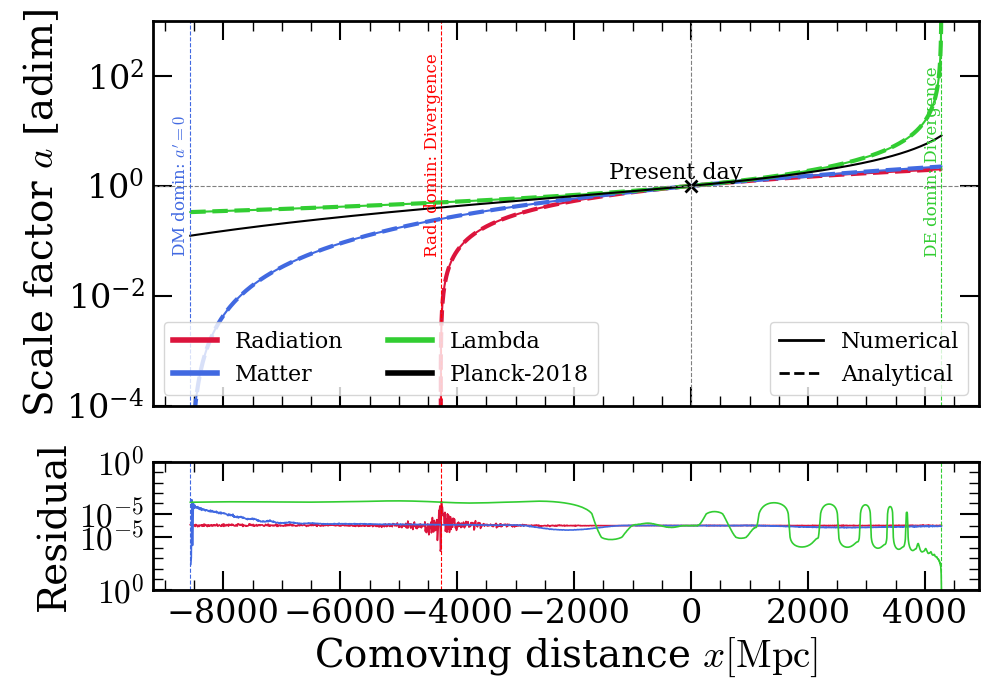

In [8]:
# Setup figure for null geodesics
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [3, 1]})

# Plot each cosmology
handles_cosmo = []
for ii, key_cosmo in enumerate(analytic_solutions.keys()):

    color = cosmo_colors[key_cosmo]
    handles_cosmo.append(Line2D([0], [0], color=color, lw=4, linestyle='-', label=key_cosmo))

    x_num, a_num = numerical_solutions[key_cosmo]
    ax1.plot(jax.device_get(x_num), jax.device_get(a_num), linestyle='-', color=color, lw=1.5)

    if analytic_solutions[key_cosmo] is not None:

        x_analytic, a_analytic = analytic_solutions[key_cosmo]
        ax1.plot(jax.device_get(x_analytic), jax.device_get(a_analytic), linestyle='--', color=color, lw=3)

        # Interpolate analytic solution
        a_interp = jnp.interp(x_num, jax.device_get(x_analytic), jax.device_get(a_analytic))
        ratio = a_num / a_interp
        ax2.plot(x_num, ratio-1, color=color, lw=1.2)

    
# Legends
legend1 = ax1.legend(handles=handles_cosmo, loc='lower left', title_fontsize=16, fontsize=16, ncol=2)
ax1.add_artist(legend1)

handles_style = [
    Line2D([0], [0], color='black', lw=2, linestyle='-', label='Numerical'),
    Line2D([0], [0], color='black', lw=2, linestyle='--', label='Analytical')
]
legend2 = ax1.legend(handles=handles_style, loc='lower right', title_fontsize=16, fontsize=16)

# === Present day ===
ax1.plot(x0, a0, marker='x', color='black', markersize=8, mew=2)
ax1.text(x0 - 1400, a0 + 0.1, "Present day", color='black', fontsize=16, va='bottom', ha='left')
ax1.axvline(x0, color='gray', linestyle='--', lw=0.8)
ax1.axhline(a0, color='gray', linestyle='--', lw=0.8)

# Configure main plot
ax1.set_ylabel("Scale factor $a$ [adim]")

distance_to_andromeda = 765.0 * 10e-6 # Gpc
ax1.axhline(-200 * distance_to_andromeda, color='k', linestyle='--', lw=1.5)

# Ratio plot
ax2.set_xlabel("Comoving distance $x [\mathrm{Mpc}]$")
ax2.set_ylabel("Residual")
# ax2.set_ylim(0.999, 1.001)

# === Divergence in DE domination ===
_divergence = x0 + 1/(a0 * phys.H0_over_c)
ax1.axvline(_divergence, color='limegreen', linestyle='--', lw=0.8)
ax2.axvline(_divergence, color='limegreen', linestyle='--', lw=0.8)
ax1.text(_divergence, 0.05, "DE domin: Divergence", 
         rotation=90, va='bottom', ha='right', color='limegreen', fontsize=12)

# === a' = 0 in DM domination (negative root) ===
_divergence = x0 - 2/phys.H0_over_c * a0**0.5
ax1.axvline(_divergence, color='royalblue', linestyle='--', lw=0.8)
ax2.axvline(_divergence, color='royalblue', linestyle='--', lw=0.8)
ax1.text(_divergence, 0.05, "DM domin: " + r"$a' = 0$",
         rotation=90, va='bottom', ha='right', color='royalblue', fontsize=12)

# === ln(a) = 0 in Radiation domination ===
_divergence = x0 - a0/phys.H0_over_c
ax1.axvline(_divergence, color='red', linestyle='--', lw=0.8)
ax2.axvline(_divergence, color='red', linestyle='--', lw=0.8)
ax1.text(_divergence, 0.05, "Rad. domin: Divergence",
         rotation=90, va='bottom', ha='right', color='red', fontsize=12)

ax1.set_yscale('log')
ax2.set_yscale('symlog', linthresh=1e-5)  # linthresh sets the range around 0 where it is linear

major_ticks = [-1e0, -1e-5, 1e-5, 1e0]
ax2.set_yticks(major_ticks)
ax2.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(sjx.utils.plotting_tools.ten_power_formatter))
ax2.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())

ax1.set_ylim(1e-4, 1e3)

plt.tight_layout()

# plt.savefig("a_of_x.pdf", bbox_inches='tight')

plt.show()

### Check calls with single and multiple cosmologies

In [9]:
# Create cosmology object
cosmo = cosmology.Cosmology(
    H0             = phys.H0,
    Omega_r_0      = 0.0,
    Omega_m_0      = 1.0,
    Omega_k_0      = 0.0,
    Omega_lambda_0 = 0.0,
)
print(cosmo.params)
_a_of_x = cosmo.solve_a_of_x(jnp.ones(cosmo.N_cosmologies), jnp.linspace(0.0, -6.0, 10))

_a_of_x.shape

[[0.07154084 0.         1.         0.         0.        ]]


(1, 10)

In [10]:
# Create cosmology object
cosmo = cosmology.Cosmology(
    H0             = jnp.array([phys.H0, phys.H0, phys.H0, phys.H0]),
    Omega_r_0      = jnp.array([1.0, 0.0, 0.0, 0.0]),
    Omega_m_0      = jnp.array([0.0, 1.0, 0.0, 0.0]),
    Omega_k_0      = jnp.array([0.0, 0.0, 1.0, 0.0]),
    Omega_lambda_0 = jnp.array([0.0, 0.0, 0.0, 1.0]),
)
print(cosmo.params)
_a_of_x = cosmo.solve_a_of_x(jnp.ones(cosmo.N_cosmologies), jnp.linspace(0.0, -6.0, 10))

_a_of_x.shape

[[0.07154084 1.         0.         0.         0.        ]
 [0.07154084 0.         1.         0.         0.        ]
 [0.07154084 0.         0.         1.         0.        ]
 [0.07154084 0.         0.         0.         1.        ]]


(4, 10)

# Check JAX auto-differentiability

In [11]:
# Create cosmology object
cosmo = cosmology.Cosmology(
    H0             = jnp.array([phys.H0, phys.H0, phys.H0, phys.H0, phys.H0]),
    Omega_r_0      = jnp.array([1.0, 0.0, 0.0, 0.0, 9.1436e-5]),
    Omega_m_0      = jnp.array([0.0, 1.0, 0.0, 0.0, 0.3089]),
    Omega_k_0      = jnp.array([0.0, 0.0, 1.0, 0.0, 0.0]),
    Omega_lambda_0 = jnp.array([0.0, 0.0, 0.0, 1.0, 0.6911]),
)

# solve for a_of_x
ICs = jnp.ones(cosmo.N_cosmologies)

x_eval = jnp.linspace(
    start=0.0,
    stop=x0 - 2/phys.H0_over_c * a0**0.5  + 0.01, # Dark Matter Fomination a' = 0 + delta,
    num=1000
)

a_of_x = cosmo.solve_a_of_x(ICs, x_eval)

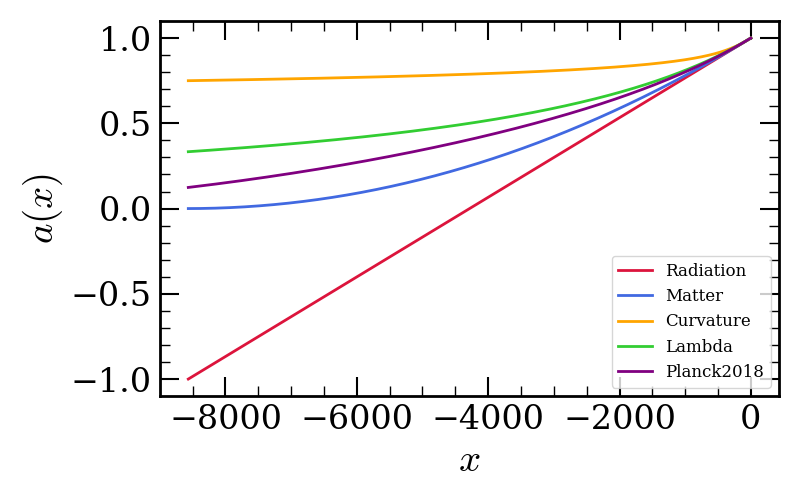

In [12]:
# plot the results as the scale factor a vs comoving distance x

# Define color map for cosmologies
cosmo_colors = {
    "Radiation": "crimson",
    "Matter": "royalblue",
    "Curvature": "orange",
    "Lambda": "limegreen",
    "Planck2018": "purple"
}

fig, ax = plt.subplots(figsize=(8, 5))
for i, cosmo in enumerate(cosmo.params):
    label = list(cosmo_colors.keys())[i]
    color = cosmo_colors[label]
    ax.plot(jax.device_get(x_eval), jax.device_get(a_of_x[i]), color=color, lw=2, label=label)

ax.legend(loc="best", fontsize=12)
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$a(x)$")

plt.tight_layout()
plt.show()